In [74]:
pip install scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [75]:
#Data
from sklearn.datasets import load_breast_cancer

#Models
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier

#Algorithms
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier
)

#Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## LOAD DATA SET

In [76]:
X, y = load_breast_cancer(return_X_y=True)

print("Features shape", X.shape)
print("Class balance\n", pd.Series(y).value_counts().rename({0: "maligant"}))

Features shape (569, 30)
Class balance
 1           357
maligant    212
Name: count, dtype: int64


## TRAIN/TEST SPLIT

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size = 0.8,
    random_state = 42,
    stratify = y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 30) | Test: (114, 30)


## DEFINE THE MODELS

In [78]:
models = {
    "Decision tree": DecisionTreeClassifier(random_state=42),
    "Bagging classifier": BaggingClassifier(random_state=42),
    "Random forest": RandomForestClassifier(random_state=42),
    "Gradient boosting": GradientBoostingClassifier(random_state=42)

}

## CHANGE RANDOM FOREST HYPERPARAMETERS

In [83]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

params = {
    'max_depth': [1, 2, 3, 5, 10],
    'min_samples_leaf': [1, 2, 5, 10, 20],
    'n_estimators': [10, 25, 50, 100]
}

grid = GridSearchCV(
    estimator=rf,
    param_grid=params,
    cv=5,
    n_jobs=-1,
    verbose=1,
    scoring='roc_auc'
)

grid.fit(X_train, y_train)

print("Best RF params:", grid.best_params_)
print(f"Best RF CV ROC-AUC: {grid.best_score_:.4f}")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best RF params: {'max_depth': 2, 'min_samples_leaf': 5, 'n_estimators': 10}
Best RF CV ROC-AUC: 0.9898


## TRAIN AND EVALUATE ALL MODELS

In [80]:
rows = []
roc_data = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC_AUC": roc_auc_score(y_test, proba),
    })
    roc_data[name] = roc_curve(y_test, proba)[:2]

## RESULTS COMPARISON TABLE

In [81]:
results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("ROC_AUC", ascending=False)
results

,Accuracy,F1,ROC_AUC
Model,,,
Random forest,0.9561,0.9655,0.9937
Gradient boosting,0.9561,0.9660,0.9907
Bagging classifier,0.9298,0.9444,0.9899
Decision tree,0.9123,0.9286,0.9157


## ROC CURVES

<function matplotlib.pyplot.show(close=None, block=None)>

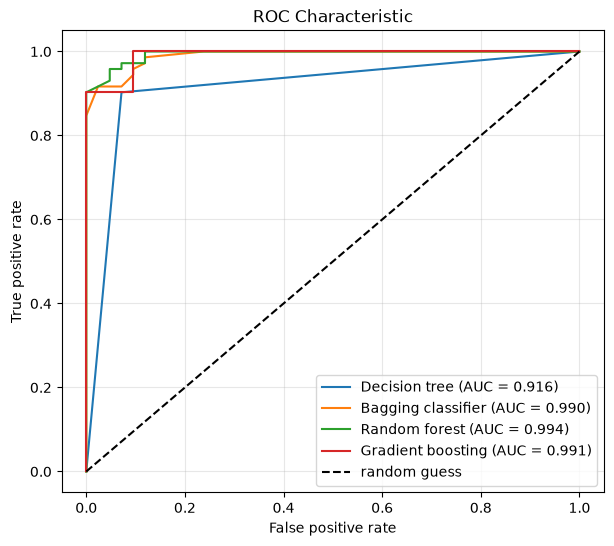

In [82]:
plt.figure(figsize=(7, 6))
for name, (fpr, tpr) in roc_data.items():
    auc = results.loc[name, "ROC_AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Characteristic")
plt.plot([0,1], [0,1], "k--", label="random guess")
plt.grid(alpha = 0.3)
plt.legend(loc="lower right")
plt.show

## CONCLUSIONS

- The Decision Tree model is clearly the weekest of all of them. It overfitted and ranked the cases worse
- Random Forest and Gradient Boosting performing is nearly the same, and the accuracy is a lot better than Decisiom Tree model
- Tuning to Random forest almost gave no gain, they almost gave the same output as default had
- The test set is small, so tiny differences between the ensembles are withing noise